In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv('/kaggle/input/datasets/mirajdeepbhandari/polynomial-regression/Ice_cream selling data.csv')
print(df.shape)
df.head()

(49, 2)


,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [6]:
X = df[['Temperature (°C)']]
y = df['Ice Cream Sales (units)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

poly = PolynomialFeatures(degree=2, include_bias=False)
Xp_train = poly.fit_transform(X_train)
Xp_test = poly.transform(X_test)

scaler = StandardScaler()
Xs_train = scaler.fit_transform(Xp_train)
Xs_test = scaler.transform(Xp_test)

y_tr = y_train.values
y_te = y_test.values

In [7]:
X = df[['Temperature (°C)']]
y = df['Ice Cream Sales (units)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

poly = PolynomialFeatures(degree=2, include_bias=False)
Xp_train = poly.fit_transform(X_train)
Xp_test = poly.transform(X_test)

scaler = StandardScaler()
Xs_train = scaler.fit_transform(Xp_train)
Xs_test = scaler.transform(Xp_test)

y_tr = y_train.values
y_te = y_test.values

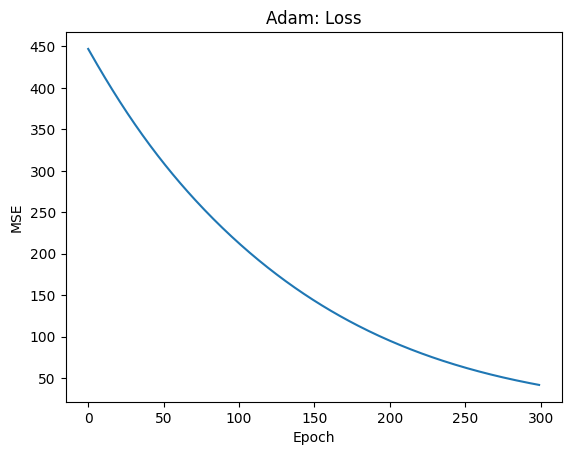

Adam -> Test RMSE: 5.40 | Test R2: 0.692


In [8]:
def evaluate(w, b, name):
    pred = Xs_test @ w + b
    rmse = np.sqrt(mean_squared_error(y_te, pred))
    r2 = r2_score(y_te, pred)
    print(f'{name} -> Test RMSE: {rmse:.2f} | Test R2: {r2:.3f}')
def adam(X, y, lr=0.05, beta1=0.9, beta2=0.999, epochs=300, eps=1e-8):
    m, n = X.shape
    w = np.zeros(n)
    b = 0.0
    mw, mb = np.zeros(n), 0.0   # Momentum
    vw, vb = np.zeros(n), 0.0   # RMSprop
    history = []
    for t in range(1, epochs + 1):
        error = (X @ w + b) - y
        dw = (2 / m) * (X.T @ error)
        db = (2 / m) * np.sum(error)

        mw = beta1 * mw + (1 - beta1) * dw
        mb = beta1 * mb + (1 - beta1) * db
        vw = beta2 * vw + (1 - beta2) * dw ** 2
        vb = beta2 * vb + (1 - beta2) * db ** 2

        mw_hat, mb_hat = mw / (1 - beta1 ** t), mb / (1 - beta1 ** t)
        vw_hat, vb_hat = vw / (1 - beta2 ** t), vb / (1 - beta2 ** t)

        w -= lr * mw_hat / (np.sqrt(vw_hat) + eps)
        b -= lr * mb_hat / (np.sqrt(vb_hat) + eps)
        history.append(np.mean(error ** 2))
    return w, b, history

w, b, hist = adam(Xs_train, y_tr)

plt.plot(hist)
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('Adam: Loss')
plt.show()

evaluate(w, b, 'Adam')